# Carteras multifactoriales

## Aproximación Top-Down

Objetivo

Construir una cartera long-only que tenga:

- Exposición positiva a Value y Momentum

- Beta próxima a la de mercado

- Volatilidad objetivo 12% anual

Paso 1. Definir “mix” de factores (objetivos)

Decides ex ante las exposiciones:
$$\beta^*_{value}=0.4,\beta^*_{mom}=0.3,\beta^*_{MKT}=1 $$



In [2]:
pip install tidyfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 15.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [tidyfinance]


In [3]:
import numpy as np
import pandas as pd
import cvxpy as cp
import datetime as dt
import yfinance as yf
import tidyfinance as tf
import missingno as mso

## 1 Obtenemos los datos de los activos y los depuramos

In [4]:
ibex35_tickers = [
    "ACS.MC","ACX.MC","AMS.MC","ANA.MC","ANE.MC",
    "AENA.MC","BBVA.MC","BKT.MC","CABK.MC","CLNX.MC",
    "COL.MC","ELE.MC","ENG.MC","FDR.MC","FER.MC",
    "GRF.MC","IAG.MC","IBE.MC","IDR.MC","ITX.MC",
    "LOG.MC","MAP.MC","MRL.MC","MTS.MC","NTGY.MC",
    "PUIG.MC","RED.MC","REP.MC","ROVI.MC","SAB.MC",
    "SAN.MC","SCYR.MC","SLR.MC","TEF.MC","UNI.MC"
]

ibex_index = "^IBEX"


In [5]:
# Últimos 5 años (aprox.)
end = dt.datetime.today()
start = end - dt.timedelta(days=5*365)

# Descarga diaria (auto-adjust) y paso a mensual (último cierre de cada mes)
px_daily = yf.download(
    ibex35_tickers,
    start=start,
    end=end,
    auto_adjust=True,
    progress=False
)["Close"]

px_monthly = px_daily.resample("ME").last()



<Axes: >

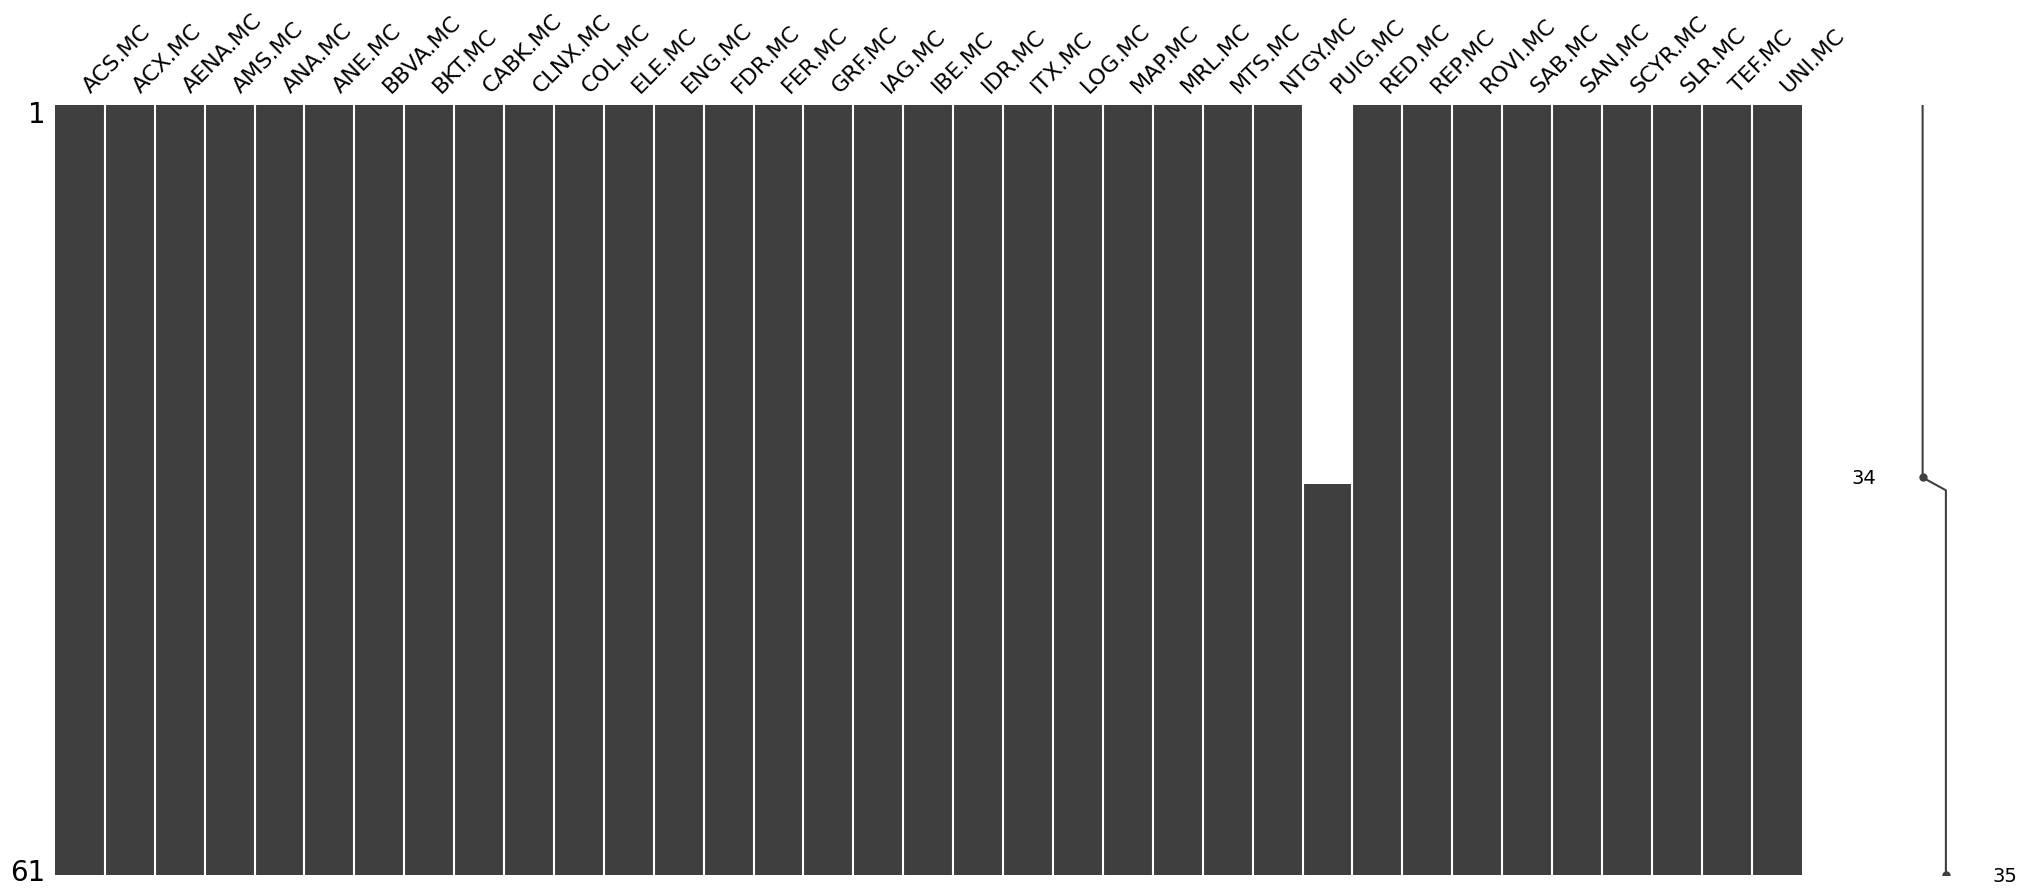

In [6]:
mso.matrix(px_monthly)

In [7]:
px_monthly=px_monthly.dropna(how="any", axis=1)

<Axes: >

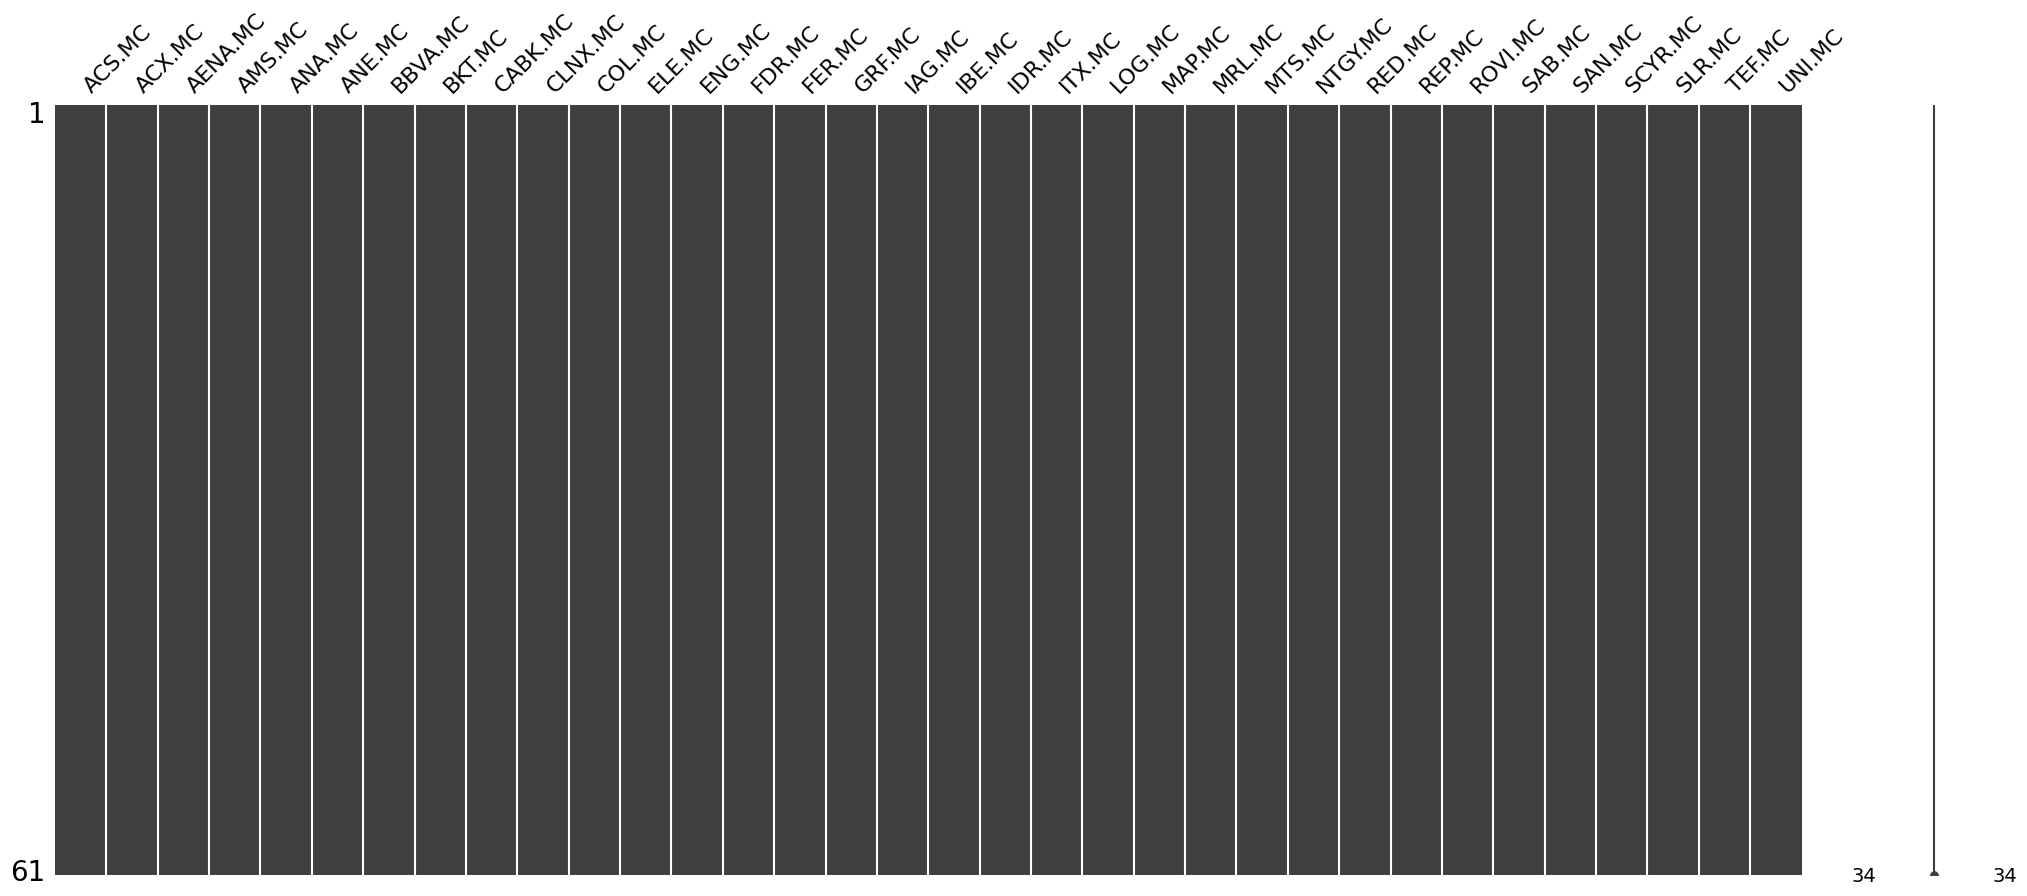

In [8]:
mso.matrix(px_monthly)

In [9]:
rets_clean=np.log(px_monthly /px_monthly.shift(1)).dropna()
rets_clean

Ticker,ACS.MC,ACX.MC,AENA.MC,AMS.MC,ANA.MC,ANE.MC,BBVA.MC,BKT.MC,CABK.MC,CLNX.MC,...,NTGY.MC,RED.MC,REP.MC,ROVI.MC,SAB.MC,SAN.MC,SCYR.MC,SLR.MC,TEF.MC,UNI.MC
Date,,,,,,,,,,,,,,,,,,,,,
2021-12-31,0.105502,0.145028,0.069353,0.054440,0.065134,0.066956,0.110134,0.048677,0.059745,-0.016664,...,0.163979,0.015360,0.063798,0.133144,-0.007743,0.066978,0.088683,0.036887,0.000909,0.110616
2022-01-31,-0.036435,-0.011928,0.030859,0.014978,-0.085660,-0.184534,0.070591,0.140658,0.164629,-0.238997,...,-0.017618,-0.045857,0.101685,-0.120836,0.149748,0.051047,-0.012593,-0.105880,0.069321,0.047200
2022-02-28,-0.021311,0.013684,0.021766,-0.009960,-0.007807,0.106025,-0.063001,-0.018278,0.032495,0.008401,...,-0.157533,-0.004757,0.033587,0.100302,0.119689,-0.036194,-0.053917,0.075938,0.035104,-0.082928
2022-03-31,0.115846,-0.133469,0.031952,-0.012760,0.125086,0.106356,-0.015238,0.055177,0.045545,0.072824,...,0.143138,0.043097,0.025309,-0.073151,-0.000272,0.037970,0.045738,0.206699,0.025969,0.117452
2022-04-30,0.003667,0.010466,-0.102752,0.020406,0.077601,0.062609,0.015387,0.056239,0.051297,0.019260,...,0.056197,0.027820,0.180657,-0.030214,-0.002148,-0.077449,0.163750,0.042641,0.054217,-0.017843
2022-05-31,0.071024,0.179259,0.042024,-0.043309,-0.043603,0.027872,0.003945,0.049534,0.086796,-0.058453,...,-0.020750,0.008068,0.048507,-0.043894,0.112993,0.067939,0.023729,0.016745,0.088162,0.030065
2022-06-30,-0.132233,-0.267200,-0.159028,-0.084374,-0.022536,0.010935,-0.159431,0.018345,-0.015258,-0.126159,...,-0.024098,-0.028533,-0.065094,-0.066249,-0.090926,-0.114636,-0.116775,-0.068235,-0.010231,0.005371
2022-07-31,0.079140,0.083629,0.014330,0.064115,0.156761,0.150181,0.019778,-0.214278,-0.124400,0.163100,...,0.041011,0.064712,-0.123203,-0.119161,-0.196996,-0.096799,-0.028295,0.104026,-0.109666,-0.100196
2022-08-31,-0.050399,-0.051415,-0.005298,-0.074325,-0.027801,-0.030889,0.016726,0.060576,0.025284,-0.117181,...,-0.030205,-0.053129,0.068525,-0.038781,0.095223,-0.009471,-0.003594,-0.059124,-0.056902,0.059754


## 2) Definimos la matriz X

La matriz $X$ es $N\times K$ donde N es el número de activos y $K$ el número de factores.
$$
X=\left[\begin{array}{ccccc}
z_{1,Value} & z_{1,Mom} & \beta_1 &\dots & Sector_M \\
z_{2,Value} & z_{2,Mom} & \beta_2 &\dots & Sector_M\\
\vdots      & \vdots & \vdots & \dots & \vdots \\
z_{N,Value} & z_{N,Mom} & \beta_N &\dots & Sector_M
\end{array}\right]
$$
Donde:
- **$z_{i,k}$** es la medida factor $j$ del activo $i$ al  normalizado.
$$z_{i,k}=\frac{señal_{i,k}-\mu_k}{\sigma_k}$$

  - $\mu_k$ y $\sigma_k$ se calculan en el corte cross-sectional del correspondiente mes.
  - Si $z_{i,k}>0$ es considerado alto con respecto al factor $k$
  - Si $z_{i,k}<0$ es considerado bajo con respecto al factor $k$

- **$Sector_m$** toma valor 1 si la empresa pertenece al sector $m$.



## 2.1. Estimamos la señal momentum

Definimos el momentum 12-2, es decir, los rendimientos acumulados desde $t-12$ hasta $t-2$:
$$MOM_{i,t}=\prod_{j=2}^{12}(1+r_{i,t-j})-1$$

In [10]:
#Estimamos el factor Momentum
# --- 1) MOM 12-2 (a partir de retornos mensuales)
R = rets_clean.copy().dropna(how="all") # por si aún quedan NAN
assets = R.columns # guarda la lista de tickers

# (1+R) acumulado de t-12..t-2 => shift(2) y rolling(11)
mom_12_2 = (1 + R).shift(2).rolling(11).apply(np.prod, raw=True) - 1 # desplazamos dos meses shift(2)
  # .rolling(11) toma una ventana móvil de 11 meses sobre los datos ya desplazados.
  # .apply(np.prod, raw=True) Para cada ventana, multiplica los 11 factores, trabaja con ndarray en lugar de con series
mom_signal = mom_12_2.iloc[-1]  # señal cross-sectional en la última fecha
mom_signal

,2026-11-30
Ticker,
ACS.MC,0.227347
ACX.MC,0.550411
AENA.MC,0.123023
AMS.MC,-0.222395
ANA.MC,0.042024
ANE.MC,-0.089708
BBVA.MC,0.455984
BKT.MC,0.285388
CABK.MC,0.418818


## 2.2. Estimamos la señal valor

In [11]:
# --- 2) VALUE proxy: 1/PB desde Yahoo
pb = {}
for tkr in assets: # recorre los tickers
    try:
        pb[tkr] = yf.Ticker(tkr).info.get("priceToBook", np.nan)
    except Exception:
        pb[tkr] = np.nan

pb = pd.Series(pb, dtype=float)
value_proxy = (1.0 / pb).rename("ValueProxy")
value_proxy

,ValueProxy
ACS.MC,0.249797
ACX.MC,0.572710
AENA.MC,0.213862
AMS.MC,0.191653
ANA.MC,0.400844
ANE.MC,0.846631
BBVA.MC,0.441433
BKT.MC,0.494527
CABK.MC,0.456016
CLNX.MC,0.735909


## 2.3 Estimamos las betas

In [12]:
# Últimos 5 años (aprox.)
end = dt.datetime.today()
start = end - dt.timedelta(days=5*365)

# Obtenemos los datos del IBEX35
mkt_px = yf.download(
    "^IBEX",
    start=start,
    end=end,
    auto_adjust=True,
    progress=False
)["Close"].dropna()

mkt_m  = mkt_px.resample("ME").last() # lo convertimos en datos mensuales
mkt_ret = np.log(mkt_m).diff(1).dropna()
mkt_ret.head()

Ticker,^IBEX
Date,
2021-12-31,0.048038
2022-01-31,-0.011659
2022-02-28,-0.015633
2022-03-31,-0.004030
2022-04-30,0.016337


In [13]:
# --- 3) Beta de mercado

# Alinear ventanas
common = R.index.intersection(mkt_ret.index) # identificamos las fechas comunes
R_al = R.loc[common] # seleccionamos las fechas comunes
mkt_al = mkt_ret.loc[common]

def estimate_beta(asset_ret: pd.Series, mkt_ret: pd.Series, min_obs=24) -> float:
    df = pd.concat([asset_ret, mkt_ret], axis=1).dropna()
    if len(df) < min_obs:
        return np.nan
    x = df.iloc[:, 1].values
    y = df.iloc[:, 0].values
    x = x - x.mean()
    y = y - y.mean()
    return float((x @ y) / (x @ x))

beta = pd.Series({tkr: estimate_beta(R_al[tkr], mkt_al) for tkr in assets}, name="MktBeta")
beta.head()

,MktBeta
ACS.MC,0.669534
ACX.MC,1.186504
AENA.MC,0.936025
AMS.MC,0.908257
ANA.MC,0.986701


In [14]:
# --- 4) Ensamblar exposiciones X (Value, Mom, Beta)
signals = pd.concat([mom_signal.rename("MomRaw"), value_proxy,beta], axis=1)

# Filtrar activos sin señal (P/B faltante o momentum NaN)
signals = signals.dropna(subset=["MomRaw", "ValueProxy","MktBeta"]).copy()#Elimina todas las filas que tengan un valor ausente en las columnas señaladas
signals.head()

,MomRaw,ValueProxy,MktBeta
ACS.MC,0.227347,0.249797,0.669534
ACX.MC,0.550411,0.572710,1.186504
AENA.MC,0.123023,0.213862,0.936025
AMS.MC,-0.222395,0.191653,0.908257
ANA.MC,0.042024,0.400844,0.986701


## 2.4. Estimamos la matriz X

In [15]:
# --- 2.4) Matriz X
def zscore(s: pd.Series) -> pd.Series: # Función para estandarizar las señales
    s = s.replace([np.inf, -np.inf], np.nan) # Si en s hay valores +inf o -inf los reemplaza por NaN.
    return (s - s.mean()) / s.std()

X = pd.DataFrame(index=signals.index) # El dataframe le llamamos X
X["Mom"] = zscore(signals["MomRaw"])
X["Value"] = zscore(signals["ValueProxy"])
X["MktBeta"] = signals["MktBeta"]

print("Activos utilizables:", len(X), "de", len(assets))
X.head()

Activos utilizables: 34 de 34


,Mom,Value,MktBeta
ACS.MC,0.293587,-0.773494,0.669534
ACX.MC,1.471743,0.128069,1.186504
AENA.MC,-0.086862,-0.873821,0.936025
AMS.MC,-1.346535,-0.935828,0.908257
ANA.MC,-0.382248,-0.351775,0.986701


# 3. Planteamos la función de optimización
Si $w$ es el vector de peso de los activos, la exposición de la cartera a los factores es:
$$b(w)=X^Tw, \text{  }w\in \mathbb{R}^K$$

Cada exposición de cartera es un promedio ponderado:

$$(X^Tw)_k=\sum_{i=1}^Nw_iX_{i,k}$$

Ahora tenemos que conseguir la siguiente optimización:

1. Tracking de exposiciones:
$$\|X^Tw-b^*\|^2_W=(X^Tw-b^*)^TW(X^Tw-b^*)=\sum_{k=1}^KW_k((B^Tw)_k-b^*_k)^2$$

- $b^*$: e s la exposición deseada.
- $W_k$ tiene distintas utilidades $(W_k\geq 0)$:
  - Permite determinar el peso (la **importancia**) que le das al error de exposición del factor $k$ dentro del término de tracking.
    - $W_k$ grande significa “no tolero” desviarme del objetivo en el factor $k$.
    - $W_k$ pequeño significa el factor es secundario; acepto desviación.
  

2. Penalización por riesgo:
$$\lambda w^T\Sigma w=\lambda \sigma^2(r_p)$$

3. Penalización por rotación
$$\tau \|w-w^{prev}\|_2^2=\tau\sum_i(w_i-w_i^{prev})^2$$
    - $\tau$ grande implica cambios suaves, coste de transacción bajos pero peor ajuste.
    - $\tau$ implica pequeña implica libertad para reconfigurar.

4. Restricciones adicionales
$$\sum_i^Nw_i=1$$
$$0\leq w_i\leq w_{max}$$

## 3.1 Estimamos la matriz de varianzas y covarianzas

In [16]:
# --- 3.1. Matriz Covarianza de la rentabilidad de los activos Sigma
Sigma = R.cov().values # Estima la covarianza y lo convertimos en un array
Sigma

array([[0.00386596, 0.00178119, 0.00122052, ..., 0.00272922, 0.00012129,
        0.00054826],
       [0.00178119, 0.0065488 , 0.00170602, ..., 0.00214563, 0.00103567,
        0.00160608],
       [0.00122052, 0.00170602, 0.00352998, ..., 0.00205017, 0.00119665,
        0.00050554],
       ...,
       [0.00272922, 0.00214563, 0.00205017, ..., 0.01692784, 0.00112901,
        0.00086229],
       [0.00012129, 0.00103567, 0.00119665, ..., 0.00112901, 0.00340408,
        0.00057237],
       [0.00054826, 0.00160608, 0.00050554, ..., 0.00086229, 0.00057237,
        0.00598361]], shape=(34, 34))

In [17]:
# Definimos la función de optimización
def topdown_cvxpy(
    X: pd.DataFrame, # las características de los activos
    Sigma: np.ndarray, # la matriz de covarianzas
    targets: pd.Series, # la definición de los factores de la cartera
    w_prev: pd.Series | None = None, # cartera de partida si la tenemos
    max_weight: float = 1, # para limitar el peso de los activos
    risk_aversion: float = 1.0, # aversión al riesgo
    turnover_weight: float = 0.0, # nivel de rotación permitida si tenemos una cartera previa
    exp_weights: pd.Series | None = None, # Pesos de W_k para determinar la importancia de los factores
    solver: str = "OSQP", # optimizador
) -> pd.Series:
    """
    min  sum_k a_k ( (B'w - b*)_k )^2 + risk_aversion * w' Σ w + turnover_weight * ||w-w_prev||^2
    s.t. sum(w)=1, 0<=w<=max_weight
    """
    assets = X.index # identificamos los tickers de los activos
    N = len(assets) # número de activos

    cols = targets.index.intersection(X.columns) # si el nombre de los "factores deseados" coincide con los factores estimados para cada acción
    if len(cols) == 0:
        raise ValueError("Targets no coincide con columnas de X.")

    B = X[cols].values          # N x K, caraterísticas de los activos, la convertimos en un array
    b = targets.loc[cols].values # Definición de los objetivos que queremos obtener

    if exp_weights is None:
        a = np.ones(len(cols)) # matriz de 1
    else:
        a = exp_weights.reindex(cols).fillna(1.0).values # reordena los pesos de W_k en el orden establecido en cols

    if w_prev is None:
        w_prev_vec = np.zeros(N) #matriz de ceros
    else:
        w_prev_vec = w_prev.reindex(assets).fillna(0.0).values # incluimos las ponderaciones de la cartera de partida ordenadas

    w = cp.Variable(N) # definimos el vector de ponderaciones

    exp_err = B.T @ w - b # definimos el  error
    exp_loss = cp.sum(cp.multiply(a, cp.square(exp_err))) # a (W) recoge la importancia de cada factor
    risk_loss = cp.quad_form(w, Sigma) # estima la varianza de la cartera
    turn_loss = cp.sum_squares(w - w_prev_vec) # estima las diferencias entre la cartera de partida y la seleccionada

    obj = cp.Minimize(exp_loss + risk_aversion * risk_loss + turnover_weight * turn_loss) # función objetivo
    cons = [cp.sum(w) == 1.0, w >= 0.0, w <= max_weight] # Restricción

    prob = cp.Problem(obj, cons)
    prob.solve(solver=solver, verbose=False)

    if w.value is None:
        raise RuntimeError(f"Optimización fallida. Status={prob.status}")

    return pd.Series(np.array(w.value).ravel(), index=assets, name="weight") # ravel() transforma un array multidimensional en un vector de una sola dimension


In [18]:
# --- Targets top-down del ejemplo 1. Sin incluir la beta de mercado
targets = pd.Series({"Value": 0.40, "Mom": 0.30})

# Pesos por exposición: priorizar cumplir Value/Mom
exp_weights = pd.Series({"Value": 10.0, "Mom": 10.0})

# (opcional) cartera previa: equal-weight para penalizar rotación
w_prev = pd.Series(1.0/len(X), index=X.index)

w_opt = topdown_cvxpy(
    X=X,
    Sigma=Sigma,
    targets=targets,
    w_prev=w_prev,
    max_weight=0.10,
    risk_aversion=1.0,
    turnover_weight=1.0,   # sube si quieres más estabilidad
    exp_weights=exp_weights,
    solver="OSQP"
)

# --- Chequeos
achieved = (X[targets.index].T @ w_opt).rename("achieved") # factores de la cartera
print(pd.concat([targets.rename("target"), achieved], axis=1))
print("\nSuma pesos:", float(w_opt.sum()), "| max:", float(w_opt.max()), "| min:", float(w_opt.min()))

w_opt.sort_values(ascending=False).head(10)


       target  achieved
Value     0.4  0.398801
Mom       0.3  0.299167

Suma pesos: 1.0000000000000002 | max: 0.06448411368142722 | min: 0.007162270676724008


,weight
COL.MC,0.064484
REP.MC,0.061578
MTS.MC,0.061255
UNI.MC,0.048143
MRL.MC,0.044760
ACX.MC,0.042604
SAN.MC,0.041076
SAB.MC,0.039035
MAP.MC,0.036251
CABK.MC,0.035735


In [19]:
# Retorno mensual de la cartera (serie)
port_rets=R@w_opt
print("Media mensual:", port_rets.mean(), " | Vol mensual:", port_rets.std())
port_rets.tail()


Media mensual: 0.014926441810101627  | Vol mensual: 0.04345322246158543


,0
Date,
2026-07-31,0.042538
2026-08-31,0.004309
2026-09-30,-0.031882
2026-10-31,-0.024042
2026-11-30,0.050680


## Incluimos la beta

In [20]:
def topdown_cvxpy(
    X: pd.DataFrame,
    Sigma: np.ndarray,
    targets: pd.Series,
    w_prev: pd.Series | None = None,
    max_weight: float = 1,
    risk_aversion: float = 1.0,
    turnover_weight: float = 0.0,
    exp_weights: pd.Series | None = None,
    solver: str = "OSQP",
    beta_vec: pd.Series | None = None,
    beta_target: float | None = None,
    beta_band: float | None = None,   # si quieres banda en lugar de igualdad exacta
) -> pd.Series:

    assets = X.index
    N = len(assets)

    cols = targets.index.intersection(X.columns)
    if len(cols) == 0:
        raise ValueError("Targets no coincide con columnas de X.")

    B = X[cols].values
    b = targets.loc[cols].values

    a = np.ones(len(cols)) if exp_weights is None else exp_weights.reindex(cols).fillna(1.0).values
    w_prev_vec = np.zeros(N) if w_prev is None else w_prev.reindex(assets).fillna(0.0).values

    w = cp.Variable(N)

    exp_err  = B.T @ w - b
    exp_loss = cp.sum(cp.multiply(a, cp.square(exp_err)))
    risk_loss = cp.quad_form(w, Sigma)
    turn_loss = cp.sum_squares(w - w_prev_vec)

    cons = [cp.sum(w) == 1.0, w >= 0.0, w <= max_weight]

    # --- Neutralidad a mercado: beta' w = beta_target (o en banda)
    if beta_vec is not None and beta_target is not None:
        beta_aligned = beta_vec.reindex(assets).astype(float).values # garantiza que coincidan los ticker de las betas y de los activos
        if beta_band is None:
            cons.append(beta_aligned @ w == beta_target)
        else:
            cons += [
                beta_aligned @ w >= beta_target - beta_band,
                beta_aligned @ w <= beta_target + beta_band
            ]

    obj = cp.Minimize(exp_loss + risk_aversion*risk_loss + turnover_weight*turn_loss)
    prob = cp.Problem(obj, cons)
    prob.solve(solver=solver, verbose=False)

    if w.value is None:
        raise RuntimeError(f"Optimización fallida. Status={prob.status}")

    return pd.Series(np.array(w.value).ravel(), index=assets, name="weight")


In [21]:
beta_target = 1
# beta_target = float(beta_vec.reindex(X.index) @ w_prev)  # benchmark-neutral

w_opt = topdown_cvxpy(
    X=X,
    Sigma=Sigma,
    targets=targets,
    w_prev=w_prev,
    max_weight=0.10,
    risk_aversion=1.0,
    turnover_weight=1.0,
    exp_weights=exp_weights,
    solver="OSQP",
    beta_vec=beta,
    beta_target=beta_target,
    beta_band=0.02          # recomendable: banda para evitar infeasible
)

# --- Chequeos
achieved = (X[targets.index].T @ w_opt).rename("achieved") # factores de la cartera
print(pd.concat([targets.rename("target"), achieved], axis=1))
print("\nSuma pesos:", float(w_opt.sum()), "| max:", float(w_opt.max()), "| min:", float(w_opt.min()))

w_opt.sort_values(ascending=False).head(10)


# check beta
beta_port = float(beta.reindex(w_opt.index).values @ w_opt.values)
print("Beta cartera:", beta_port)


       target  achieved
Value     0.4  0.398893
Mom       0.3  0.299153

Suma pesos: 0.9999999999999997 | max: 0.06568220816407135 | min: 0.007847070333838108
Beta cartera: 0.9799999999999999
